# 01 · Linear MPC

A chain of six masses joined by springs, with three actuators pulling on pairs of masses, has to stay still while
random forces kick it (the "oscillating masses" example of Wang & Boyd's fast-MPC paper). At every sampling instant
the controller solves the constrained linear MPC problem

$$
\min_{x,u}\ \sum_{t=0}^{N-1}\tfrac12\big(x_t^\top Q x_t + u_t^\top R u_t\big) + \tfrac12 x_N^\top Q_N x_N
\quad\text{s.t.}\quad x_0=\bar x,\ \ x_{t+1}=Ax_t+Bu_t,\ \ |u_t|\le u_{\max},\ \ |x_t|\le x_{\max}.
$$

This notebook shows how to use ParaMPC for linear MPC:

1. build the QP with `make_qp` and `add_bounds`;
2. solve it with `solve_qp` on every available backend, and certify the answer with an independent dense KKT
   check (`parampc.testing`);
3. run the closed loop, warm-starting each QP from the previous solution (`Solution.shift`);
4. solve a batch of QPs in one call with `jax.vmap`.

`solve_qp` is a primal-dual interior-point method whose Newton steps are solved by associative scans over the
horizon ($\Theta(\log N)$ depth), on the `'scan'` backend (XLA, CPU or GPU) or the `'cuda'` backend (the whole
solve as one GPU kernel). The `'sweep'` backend runs the same method with the sequential Riccati recursion
instead of the scans; it is usually the fastest on a CPU.

## 0. Import Dependencies

In [1]:
import time

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import scipy.linalg as sla

import parampc as pm
from parampc.models import linear

%config InlineBackend.figure_formats = ['svg']    # figures as vector graphics

print(f"parampc {pm.__version__} | jax {jax.__version__} | devices {jax.devices()} | "
      f"backends {pm.available_backends()}")

parampc 0.1.0 | jax 0.11.1 | devices [CudaDevice(id=0)] | backends ['cuda', 'scan', 'sweep']


## 1. Parameter Declaration

**Plant.** Six unit masses in a row, joined to each other and to two walls by unit springs; actuator $j$ pulls
masses $2j-1$ and $2j$ towards each other. State $x = (p_1..p_6, v_1..v_6) \in \mathbb R^{12}$, input
$u\in\mathbb R^3$, exact zero-order-hold discretization with $\Delta t = 0.5$ s. The plant is undamped: its
eigenvalues lie on the unit circle.

**Controller.** Horizon $N = 30$, $Q = I$, $R = I$, and $Q_N$ the solution of the discrete algebraic Riccati
equation, so the unconstrained tail is costed exactly. Limits $|u_i| \le 0.5$, $|x_i| \le 4$.

**Disturbance.** Each velocity receives a uniform random kick in $[-0.1, 0.1]$ m/s every step.

In [2]:
# plant
N_MASSES, SPRING, DT = 6, 1.0, 0.5
ACTUATED_PAIRS = ((0, 1), (2, 3), (4, 5))      # actuator j pulls on masses (a, b)

# controller
N = 30                                          # horizon
U_MAX, X_MAX = 0.5, 4.0                         # |u_i| <= U_MAX, |x_i| <= X_MAX
TOL = 1e-8                                      # the IPM stops when the KKT score is below this
BACKEND = 'auto'                                # 'cuda' on a GPU with nvcc, else 'sweep' on a CPU

# closed loop
STEPS = 100
W_MAX = 0.1                                     # velocity kicks ~ U(-W_MAX, W_MAX)
SEED = 0
X_INIT_POS = 1.5                                # masses start displaced alternately by +-1.5 m
BATCH = 64                                      # initial states solved together in Section 3c

## 2. Building the QP

`make_qp(A, B, Q, R, N, x0, QN)` builds an `OCPQP`, the general time-varying MPC QP

$$
\min\ \sum_t \tfrac12 x_t^\top Q_t x_t + u_t^\top S_t x_t + \tfrac12 u_t^\top R_t u_t + q_t^\top x_t + r_t^\top u_t
+ \tfrac12 x_N^\top Q_N x_N + q_N^\top x_N
\quad\text{s.t.}\quad x_{t+1} = A_t x_t + B_t u_t + c_t,\ \ C_t x_t + D_t u_t \le d_t,\ \ C_N x_N \le d_N .
$$

Data without the leading stage axis is broadcast to all $N$ stages. `add_bounds` appends box constraints as
inequality rows; state bounds apply to $x_1..x_{N-1}$ ($x_0$ is fixed), and `xN_min`, `xN_max` would add
terminal rows. An `OCPQP` is a pytree, so `qp.replace(x0=...)` gives the next MPC step's QP without rebuilding
anything, and QPs can be traced, jitted and vmapped.

In [3]:
A, B = linear.oscillating_masses(N_MASSES, SPRING, DT, ACTUATED_PAIRS)
n, m = B.shape
Q, R = np.eye(n), np.eye(m)
QN = sla.solve_discrete_are(A, B, Q, R)

x_init = np.zeros(n)
x_init[:N_MASSES] = X_INIT_POS * (-1.0) ** np.arange(N_MASSES)
qp = pm.make_qp(A, B, Q, R, N=N, x0=x_init, QN=QN)
qp = pm.add_bounds(qp, u_min=-U_MAX, u_max=U_MAX, x_min=-X_MAX, x_max=X_MAX)

eig = np.abs(np.linalg.eigvals(A))
print(f"n = {qp.nx} states, m = {qp.nu} inputs, N = {qp.N} stages, M = {qp.M} inequality rows per stage")
print(f"|eig(A)| in [{eig.min():.4f}, {eig.max():.4f}] (undamped)")

n = 12 states, m = 3 inputs, N = 30 stages, M = 30 inequality rows per stage
|eig(A)| in [1.0000, 1.0000] (undamped)


## 3. Solving

**3a. One QP, every backend.** `solve_qp` returns a `Solution`: states `x` $(N{+}1, n)$, inputs `u` $(N, m)$,
the multipliers `nu`, `lam` and slacks `s`, and the statistics `iters`, `kkt` (the KKT score of the returned
point on this QP) and `status` (0: solved). The point is then checked by `parampc.testing.kkt_certificate`, which
builds the QP as one dense problem in NumPy and evaluates the KKT conditions there; it shares no code with the
solver.

**3b. Closed loop.** At every step: measure $x$, solve the MPC problem from the previous solution shifted by one
stage (a warm start), apply $u_0$, add the random kick. The solver is compiled once (`jax.jit`), on the first
call, since every QP has the same shapes.

**3c. A batch.** `jax.vmap` over initial states solves many QPs in one call. On `'scan'` and `'cuda'` the batch
becomes one QP with a long horizon, which is what the parallel method is good at. The batch shares the IPM's
iterations and its stopping test, whose duality measure is averaged over the QPs, so each QP's own KKT score can
sit up to about `BATCH` times above the tolerance.

In [4]:
# ---- 3a. one QP on every backend, checked against the dense KKT certificate
solutions, certificates = {}, {}
for backend in pm.available_backends():
    solutions[backend] = pm.solve_qp(qp, tol=TOL, backend=backend)
    certificates[backend] = pm.testing.kkt_certificate(qp, solutions[backend])
ref = solutions[pm.available_backends()[-1]]
backend_gap = max(float(jnp.max(jnp.abs(s.u - ref.u))) for s in solutions.values())

# ---- 3b. closed loop with warm starts
solve = jax.jit(lambda qp, warm: pm.solve_qp(qp, warm, tol=TOL, backend=BACKEND))
cold = solve(qp, None)                                          # compiles the cold start ...
jax.block_until_ready(solve(qp, cold.shift()))                  # ... and the warm start (a different signature)
rng = np.random.default_rng(SEED)
x, sol = x_init.copy(), cold
log = dict(x=[], u=[], iters=[], ms=[], kkt=[], status=[])
for k in range(STEPS):
    warm = sol.shift() if k else None
    t0 = time.perf_counter()
    sol = jax.block_until_ready(solve(qp.replace(x0=x), warm))
    log['ms'].append(1e3 * (time.perf_counter() - t0))
    u = np.asarray(sol.u[0])
    for key, val in (('x', x), ('u', u), ('iters', int(sol.iters)), ('kkt', float(sol.kkt)),
                     ('status', int(sol.status))):
        log[key].append(val)
    w = np.concatenate([np.zeros(N_MASSES), rng.uniform(-W_MAX, W_MAX, N_MASSES)])
    x = A @ x + B @ u + w
log = {key: np.array(val) for key, val in log.items()}

# ---- 3c. a batch of initial states in one call
x0s = jnp.asarray(log['x'][rng.choice(STEPS, BATCH)])
batch = jax.jit(jax.vmap(lambda x0: pm.solve_qp(qp.replace(x0=x0), tol=TOL, backend=BACKEND)))
one = jax.jit(lambda x0: pm.solve_qp(qp.replace(x0=x0), tol=TOL, backend=BACKEND))
sols = jax.block_until_ready(batch(x0s))
singles = [one(x0) for x0 in x0s]


def median_ms(f, *args, reps=20):
    for _ in range(3):
        jax.block_until_ready(f(*args))
    times = []
    for _ in range(reps):
        t0 = time.perf_counter()
        jax.block_until_ready(f(*args))
        times.append(time.perf_counter() - t0)
    return 1e3 * float(np.median(times))


t_batch, t_one = median_ms(batch, x0s), median_ms(one, x0s[0])
obj = lambda x0, s: pm.testing.objective(qp.replace(x0=x0), s)
batch_gap = max(abs(obj(x0, jax.tree.map(lambda a: a[i], sols)) - obj(x0, s)) / (1 + abs(obj(x0, s)))
                for i, (x0, s) in enumerate(zip(x0s, singles)))

## 4. Plotting/Printing Results

In [5]:
print("== 3a. one QP (the initial state), every backend")
for backend, s in solutions.items():
    c = certificates[backend]
    print(f"   {backend:5s}: {pm.STATUS[int(s.status)]}, {int(s.iters)} IPM iterations, KKT score {float(s.kkt):.1e}; "
          f"dense certificate: stationarity {c['stationarity']:.1e}, complementarity {c['complementarity']:.1e}, "
          f"objective {c['objective']:.8f}")
print(f"   largest difference of u between backends: {backend_gap:.1e}")

print(f"\n== 3b. closed loop, {STEPS} steps on '{pm.backends.resolve_backend(BACKEND)}'")
print(f"   max |u|                 {np.abs(log['u']).max():.4f}   (limit {U_MAX})")
print(f"   max |x|                 {np.abs(log['x']).max():.4f}   (limit {X_MAX})")
print(f"   steps with |u| at limit {int(np.sum(np.isclose(np.abs(log['u']).max(1), U_MAX, atol=1e-6)))}")
print(f"   IPM iterations          cold start {int(cold.iters)}, warm starts mean {log['iters'][1:].mean():.1f}, "
      f"max {log['iters'][1:].max()}")
print(f"   KKT score at return     max {log['kkt'].max():.1e}; all solved: {bool(np.all(log['status'] == 0))}")
print(f"   solve time [ms]         median {np.median(log['ms']):.2f}, max {log['ms'].max():.2f}")

print(f"\n== 3c. a batch of {BATCH} QPs in one call")
print(f"   {t_batch:.2f} ms for the batch ({t_batch / BATCH:.3f} ms per QP) against {t_one:.2f} ms for one QP: "
      f"{t_one * BATCH / t_batch:.1f}x the throughput; {int(np.sum(np.asarray(sols.status) == 0))}/{BATCH} solved")
print(f"   each QP's own KKT score at most {float(jnp.max(sols.kkt)):.1e}; "
      f"largest relative objective difference to the single solves {batch_gap:.1e}")

assert all(c['stationarity'] < 1e-7 and c['complementarity'] < 1e-7 for c in certificates.values())
assert backend_gap < 1e-6 and batch_gap < 1e-6       # the duality gap tol allows: about N M tol relative to the cost
assert np.all(log['status'] == 0) and np.abs(log['u']).max() <= U_MAX + 1e-9 and np.abs(log['x']).max() <= X_MAX
print("\nPASS: every backend returns the certified optimum; the closed loop stays within all limits")

== 3a. one QP (the initial state), every backend
   cuda : solved, 10 IPM iterations, KKT score 8.2e-11; dense certificate: stationarity 8.2e-11, complementarity 9.8e-12, objective 115.29598503
   scan : solved, 10 IPM iterations, KKT score 8.2e-11; dense certificate: stationarity 8.2e-11, complementarity 9.8e-12, objective 115.29598503
   sweep: solved, 10 IPM iterations, KKT score 8.2e-11; dense certificate: stationarity 8.2e-11, complementarity 9.8e-12, objective 115.29598503
   largest difference of u between backends: 1.3e-15

== 3b. closed loop, 100 steps on 'cuda'
   max |u|                 0.5000   (limit 0.5)
   max |x|                 2.6698   (limit 4.0)
   steps with |u| at limit 19
   IPM iterations          cold start 10, warm starts mean 3.8, max 7
   KKT score at return     max 9.3e-09; all solved: True
   solve time [ms]         median 2.14, max 7.27

== 3c. a batch of 64 QPs in one call
   41.43 ms for the batch (0.647 ms per QP) against 2.45 ms for one QP: 3.8x the t

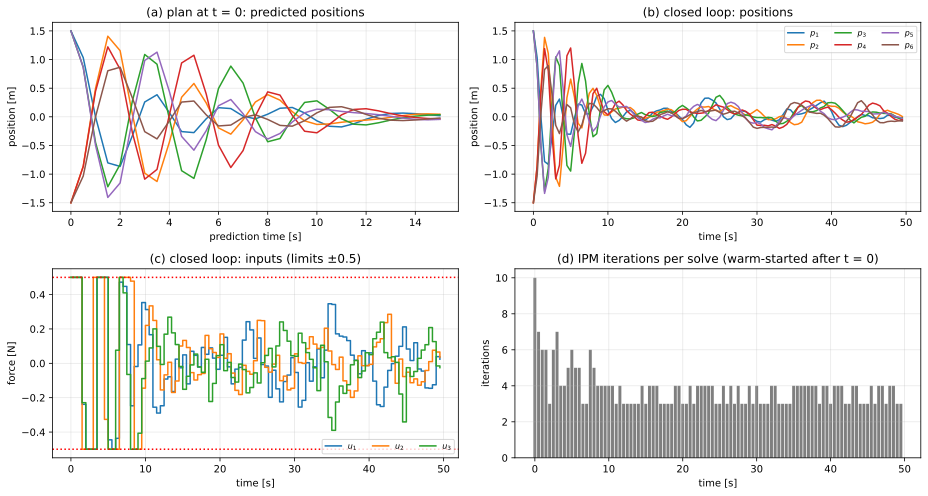

In [6]:
t = np.arange(STEPS) * DT
th = np.arange(N + 1) * DT
fig, ax = plt.subplots(2, 2, figsize=(13, 7))
ax[0, 0].plot(th, np.asarray(cold.x)[:, :N_MASSES])
ax[0, 0].set(title='(a) plan at t = 0: predicted positions', xlabel='prediction time [s]', ylabel='position [m]')
ax[0, 1].plot(t, log['x'][:, :N_MASSES])
ax[0, 1].set(title='(b) closed loop: positions', xlabel='time [s]', ylabel='position [m]')
ax[1, 0].step(t, log['u'], where='post')
for bound in (U_MAX, -U_MAX):
    ax[1, 0].axhline(bound, color='r', ls=':')
ax[1, 0].set(title=r'(c) closed loop: inputs (limits $\pm0.5$)', xlabel='time [s]', ylabel='force [N]')
ax[1, 1].bar(t, log['iters'], width=0.8 * DT, color='tab:gray')
ax[1, 1].set(title='(d) IPM iterations per solve (warm-started after t = 0)', xlabel='time [s]', ylabel='iterations')
ax[0, 1].legend([f'$p_{i + 1}$' for i in range(N_MASSES)], ncol=3, fontsize=8)
ax[1, 0].legend([f'$u_{j + 1}$' for j in range(m)], ncol=3, fontsize=8, loc='lower right')
for a in ax.ravel():
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Reading the results.**
- Every backend returns the same point to round-off, and the dense certificate confirms it is the optimum of the
  QP: stationarity, feasibility and complementarity all at the tolerance.
- The inputs saturate for the first ~10 s while the initial swing is damped; after that the controller only
  rejects the small kicks. The IPM handles the changing active set through the barrier weights inside the
  condensed Hessians, so the problem structure the scan sees never changes.
- Warm starts from the shifted previous solution cut the IPM iterations by about half.
- At $N = 30$ the parallel method has no advantage over a sequential solver; its depth matters for long horizons
  and batches (`notebooks/benchmarking`).